# 05 - Interpretation: do the 5 positions really exist?

**Goal of this notebook:** answer the question of the project. We describe what each K-Means group is, compare the groups with the official positions, and measure how much they agree.

Steps:
1. Profile each group with real numbers and give it a name.
2. Cross groups with positions in a table.
3. Measure the agreement with the adjusted Rand index, and judge it against two references.
4. Apply the silhouette to the official positions.
5. Look at the players whose group is not the usual one for their position.
6. Save a file for Tableau.

**Input:** files from notebooks 02, 03 and 04
**Output:** `data/processed/tableau_players.csv`

## 1. Imports and settings

`CLUSTER_NAMES` is **our interpretation** of each group, written after looking at the profiles in section 3. K-Means only returns numbers (0, 1, 2...): the names are ours, and they are tied to the group numbers saved in notebook 03. If you refit K-Means with another random seed the numbers change and the names have to be assigned again.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

FEATURES_PATH = Path("../data/processed/players_features.csv")
SCALED_PATH = Path("../data/processed/players_scaled.csv")
LABELS_PATH = Path("../data/processed/cluster_labels.csv")
PCA_PATH = Path("../data/processed/pca_coordinates.csv")
TABLEAU_PATH = Path("../data/processed/tableau_players.csv")

POSITION_ORDER = ["PG", "SG", "SF", "PF", "C"]
K_MAIN = 5
N_INIT = 10
N_SHUFFLES = 200
RANDOM_STATE = 42

CLUSTER_NAMES = {
    3: {0: "Creators and scorers", 1: "Perimeter role players", 2: "Rim-protecting bigs"},
    5: {
        0: "High-usage scorers",
        1: "Lead ball handlers",
        2: "Perimeter role players",
        3: "Disruptive defenders",
        4: "Rim-protecting bigs",
    },
}

In [2]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
NEUTRAL = "#f0efec"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # first three slots of the categorical palette
NEGATIVE = "#e34948"
HIGHLIGHT = SERIES[0]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "text.color": INK,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

DIVERGING = LinearSegmentedColormap.from_list("diverging", [NEGATIVE, NEUTRAL, HIGHLIGHT])
SEQUENTIAL = LinearSegmentedColormap.from_list("sequential", ["#cde2fb", "#2a78d6", "#0d366b"])

## 2. Load and combine

Real-unit features (notebook 02), group of each player (notebook 03). Joined by `player_id`. We also load the scaled features, needed for the silhouette and the stability reference.

In [3]:
df = pd.read_csv(FEATURES_PATH)
labels = pd.read_csv(LABELS_PATH)

FEATURES = [col for col in df.columns if col.endswith("_per36")]
label_columns = [col for col in labels.columns if col.startswith("kmeans_k")]
df = df.merge(labels[["player_id"] + label_columns], on="player_id", validate="one_to_one")

for k, names in CLUSTER_NAMES.items():
    df[f"cluster_k{k}"] = df[f"kmeans_k{k}"].map(names)

X = pd.read_csv(SCALED_PATH).set_index("player_id").loc[df["player_id"], FEATURES].to_numpy()
df.shape

(325, 26)

Before interpreting, a sanity check: the number of players per group, next to the name we give it.

In [4]:
pd.DataFrame({
    "name": pd.Series(CLUSTER_NAMES[K_MAIN]),
    "players": df[f"kmeans_k{K_MAIN}"].value_counts().sort_index(),
})

,name,players
0,High-usage scorers,42
1,Lead ball handlers,67
2,Perimeter role players,122
3,Disruptive defenders,49
4,Rim-protecting bigs,45


## 3. What is each group?

Two views of the same thing. The table has the **average per 36 minutes in real units** of each group. The heatmap shows how far each group is from the average player, in standard deviations (the scaled units from notebook 02): blue means above the average player, red below, and the number is how many standard deviations.

In [5]:
def cluster_order(k):
    return [CLUSTER_NAMES[k][i] for i in sorted(CLUSTER_NAMES[k])]


def cluster_profile(k):
    return df.groupby(f"cluster_k{k}")[FEATURES].mean().loc[cluster_order(k)]


def annotated_heatmap(ax, values, row_labels, col_labels, cmap, vmin, vmax, text, dark):
    ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(col_labels)), col_labels, rotation=40, ha="right")
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, text[i][j], ha="center", va="center", fontsize=9,
                    color="#ffffff" if dark(values[i, j]) else INK)


def plot_profile(k):
    means = cluster_profile(k)
    z_scores = (means - df[FEATURES].mean()) / df[FEATURES].std(ddof=0)
    fig, ax = plt.subplots(figsize=(8.5, 0.8 * len(z_scores) + 1.8))
    annotated_heatmap(
        ax, z_scores.to_numpy(), z_scores.index, [col.replace("_per36", "") for col in z_scores.columns],
        DIVERGING, -2, 2, [[f"{v:+.1f}" for v in row] for row in z_scores.to_numpy()],
        dark=lambda v: abs(v) > 1.2,
    )
    ax.set_title(f"Group profile, k={k}: standard deviations from the average player")
    fig.tight_layout()
    return fig

### 3.1 k = 5

Real units first (per 36 minutes):

In [6]:
cluster_profile(5).round(1)

,fg2a_per36,fg3a_per36,fta_per36,orb_per36,drb_per36,ast_per36,stl_per36,blk_per36,tov_per36
cluster_k5,,,,,,,,,
High-usage scorers,12.5,4.6,6.6,1.7,6.0,5.2,1.2,0.7,2.8
Lead ball handlers,8.9,6.8,4.2,0.9,3.8,6.3,1.3,0.4,2.9
Perimeter role players,5.8,6.7,2.5,1.3,4.2,3.0,1.0,0.6,1.6
Disruptive defenders,5.7,5.3,2.2,1.7,4.3,3.4,1.9,0.7,1.7
Rim-protecting bigs,8.9,1.8,3.6,4.1,7.1,2.6,1.1,1.7,1.7


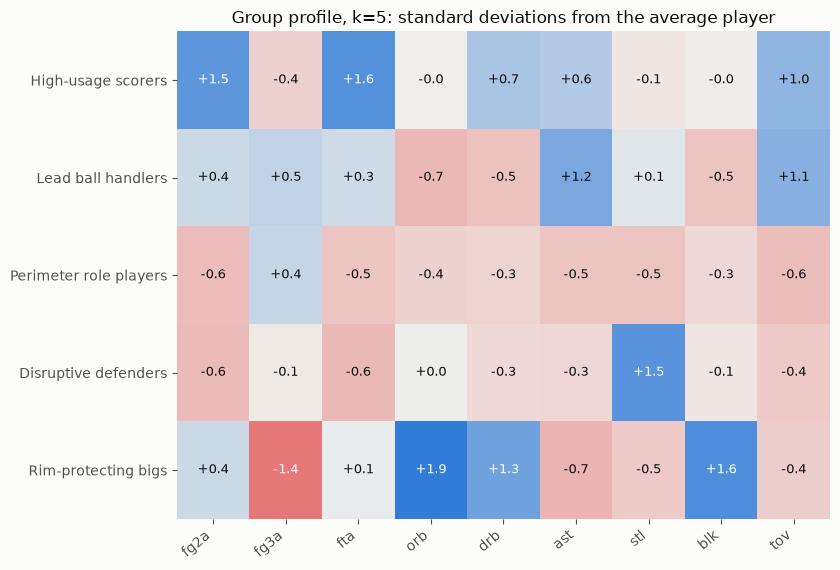

In [7]:
fig = plot_profile(5)

The most-played players of each group help check that the names make sense:

In [8]:
examples = (
    df.sort_values("minutes_per_game", ascending=False)
    .groupby("cluster_k5")["player"]
    .apply(lambda players: ", ".join(players.head(6)))
    .loc[cluster_order(5)]
)
examples.to_frame("most-played players")

,most-played players
cluster_k5,
High-usage scorers,"Amen Thompson, Kevin Durant, Luka Dončić, Jale..."
Lead ball handlers,"Tyrese Maxey, Jamal Murray, Jalen Brunson, Jam..."
Perimeter role players,"Trey Murphy III, Jabari Smith Jr., Keegan Murr..."
Disruptive defenders,"VJ Edgecombe, OG Anunoby, Dyson Daniels, Kelly..."
Rim-protecting bigs,"Evan Mobley, Rudy Gobert, Ivica Zubac, Victor ..."


How we read the heatmap:

- **High-usage scorers:** many 2-point attempts, free throws and turnovers, good defensive rebounding. Players who take the offense on their shoulders and attack the basket.
- **Lead ball handlers:** the highest assists and turnovers, and few rebounds and blocks: the players who run the offense from the perimeter.
- **Perimeter role players:** below the average player in almost everything except 3-point attempts. The biggest group by far.
- **Disruptive defenders:** an extreme in steals, average or below elsewhere.
- **Rim-protecting bigs:** very high rebounds and blocks, almost no 3-point attempts.

These names are interpretations, and it is fine to disagree with them: that is why the table of examples is there.

### 3.2 k = 3

The stable solution from notebook 03.

In [9]:
cluster_profile(3).round(1)

,fg2a_per36,fg3a_per36,fta_per36,orb_per36,drb_per36,ast_per36,stl_per36,blk_per36,tov_per36
cluster_k3,,,,,,,,,
Creators and scorers,10.7,5.9,5.3,1.2,4.7,5.8,1.3,0.5,2.9
Perimeter role players,5.6,6.4,2.4,1.3,4.1,3.3,1.3,0.6,1.6
Rim-protecting bigs,8.9,2.1,3.7,3.9,7.2,2.7,1.1,1.6,1.8


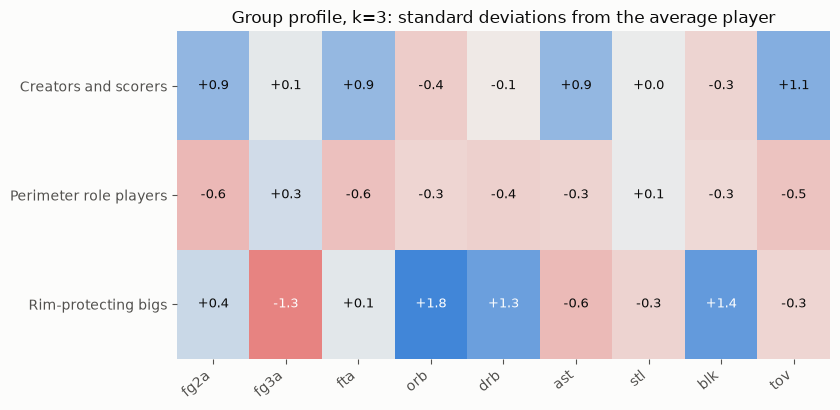

In [10]:
fig = plot_profile(3)

With three groups the picture is simpler: creators and scorers, rim-protecting bigs, and everyone else in a big perimeter group.

## 4. Groups against positions

A table crossing positions (rows) and groups (columns). Each cell shows the **share of that position** that falls in that group, and between parentheses the number of players. Reading a row answers "where do the players of this position go?".

In [11]:
def position_table(k):
    counts = pd.crosstab(df["position"], df[f"cluster_k{k}"])
    return counts.reindex(index=POSITION_ORDER, columns=cluster_order(k)).fillna(0).astype(int)


def plot_position_table(k):
    counts = position_table(k)
    shares = counts.div(counts.sum(axis=1), axis=0) * 100
    text = [[f"{shares.iat[i, j]:.0f}%\n({counts.iat[i, j]})" for j in range(counts.shape[1])]
            for i in range(counts.shape[0])]
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    annotated_heatmap(ax, shares.to_numpy(), shares.index, shares.columns, SEQUENTIAL, 0, 100, text,
                      dark=lambda v: v > 45)
    ax.set_title(f"Where does each position go? k={k}")
    fig.tight_layout()
    return fig

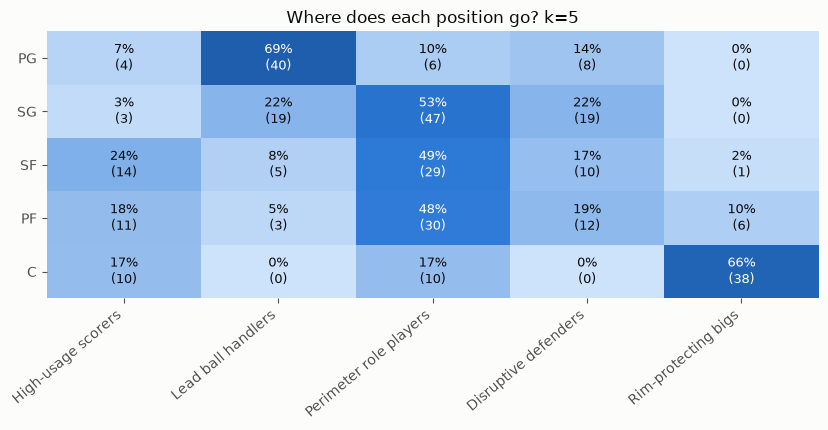

In [12]:
fig = plot_position_table(5)

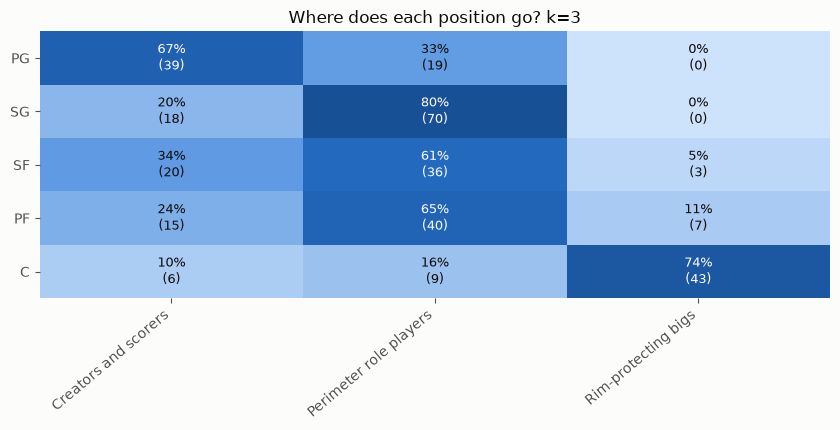

In [13]:
fig = plot_position_table(3)

Remember the two extremes from the theory: if groups and positions were the same thing, every row would have one cell at 100%. If they were unrelated, every row would look like the overall group sizes.

## 5. How much do they agree?

We cannot compare labels directly (group "0" is not "PG"), so we use the **adjusted Rand index**, which compares two ways of splitting the same players. 1 means identical splits, around 0 means the agreement of two random splits.

To judge the value we need two references, both computed for every k:

- **Chance:** shuffle the positions at random many times and compute the index each time. We keep the 95th percentile: a value above it would be very unlikely by luck.
- **Stability:** how much K-Means agrees with itself when it restarts from other random seeds (notebook 03). This is the highest agreement we can expect from a split of these players.

In [14]:
position_labels = df["position"].to_numpy()
rng = np.random.default_rng(RANDOM_STATE)

rows = []
for k in range(2, 11):
    group_labels = df[f"kmeans_k{k}"].to_numpy()
    chance = [adjusted_rand_score(rng.permutation(position_labels), group_labels) for _ in range(N_SHUFFLES)]
    other_seeds = [
        adjusted_rand_score(group_labels, KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit(X).labels_)
        for seed in range(1, 6)
    ]
    rows.append({
        "k": k,
        "vs_positions": adjusted_rand_score(position_labels, group_labels),
        "chance_p95": np.percentile(chance, 95),
        "kmeans_vs_other_seeds": np.mean(other_seeds),
    })

agreement = pd.DataFrame(rows).set_index("k")
agreement.round(3)

,vs_positions,chance_p95,kmeans_vs_other_seeds
k,,,
2,0.149,0.007,0.973
3,0.158,0.008,1.000
4,0.139,0.010,0.924
5,0.176,0.009,0.712
6,0.169,0.009,0.749
7,0.159,0.009,0.540
8,0.161,0.008,0.689
9,0.149,0.008,0.583
10,0.128,0.009,0.636


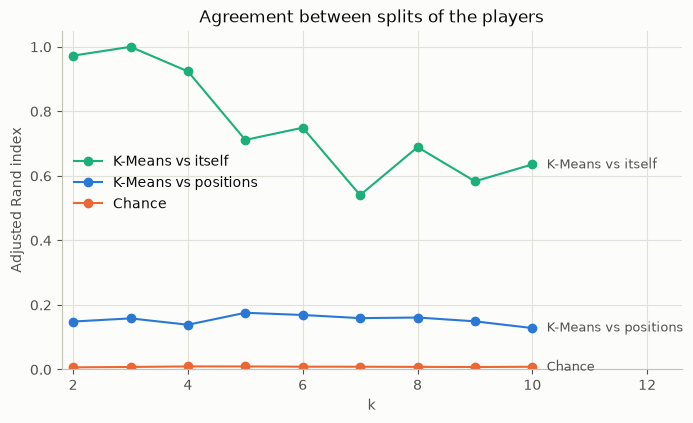

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.4))
lines = [
    ("kmeans_vs_other_seeds", SERIES[2], "K-Means vs itself"),
    ("vs_positions", SERIES[0], "K-Means vs positions"),
    ("chance_p95", SERIES[1], "Chance"),
]
for column, color, label in lines:
    ax.plot(agreement.index, agreement[column], marker="o", color=color, label=label)
    ax.text(10.25, agreement[column].iloc[-1], label, color=INK_SECONDARY, va="center", fontsize=9)
ax.set_xlim(1.8, 12.6)
ax.set_ylim(0, 1.05)
ax.set_xlabel("k")
ax.set_ylabel("Adjusted Rand index")
ax.set_title("Agreement between splits of the players")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0.0, 0.55));

## 6. Silhouette of the official positions

We apply the same silhouette from notebook 03, but taking the five official positions as the groups. A value near 0 means the groups overlap completely: a player is, on average, as close to the players of other positions as to those of his own.

Careful with the comparison: K-Means *optimizes* compactness, so it is expected to score higher. The informative number is the one for the positions.

In [16]:
pd.Series({
    "Official positions (5 groups)": silhouette_score(X, position_labels),
    "K-Means, k=3": silhouette_score(X, df["kmeans_k3"]),
    "K-Means, k=5": silhouette_score(X, df["kmeans_k5"]),
}, name="silhouette").round(3)

Official positions (5 groups)    0.018
K-Means, k=3                     0.251
K-Means, k=5                     0.178
Name: silhouette, dtype: float64

## 7. Players outside the usual group of their position

For each position we take the group where most of its players fall (the "usual" group) and check which players are somewhere else.

In [17]:
main_column = f"cluster_k{K_MAIN}"
usual_group = position_table(K_MAIN).idxmax(axis=1)
df["in_usual_group"] = df[main_column] == df["position"].map(usual_group)

pd.DataFrame({
    "usual group": usual_group,
    "share of the position in it": df.groupby("position")["in_usual_group"].mean().reindex(POSITION_ORDER).round(2),
})

,usual group,share of the position in it
position,,
PG,Lead ball handlers,0.69
SG,Perimeter role players,0.53
SF,Perimeter role players,0.49
PF,Perimeter role players,0.48
C,Rim-protecting bigs,0.66


Centers that are *not* in the rim-protecting group, ordered by minutes per game:

In [18]:
outside = df[(df["position"] == "C") & ~df["in_usual_group"]]
outside.sort_values("minutes_per_game", ascending=False)[["player", "team", main_column, "minutes_per_game"]].head(12).round(1)

,player,team,cluster_k5,minutes_per_game
42,Nikola Jokić,DEN,High-usage scorers,34.8
24,Alperen Şengün,HOU,High-usage scorers,33.3
28,Bam Adebayo,MIA,High-usage scorers,32.4
231,Joel Embiid,PHI,High-usage scorers,31.6
35,Onyeka Okongwu,ATL,Perimeter role players,31.0
33,Karl-Anthony Towns,NYK,High-usage scorers,31.0
175,Jaren Jackson Jr.,2TM,High-usage scorers,30.3
37,Wendell Carter Jr.,ORL,Perimeter role players,29.3
92,Myles Turner,MIL,Perimeter role players,26.9
263,Jusuf Nurkić,UTA,High-usage scorers,26.4


And the example that started the project:

In [19]:
df[df["player"].isin(["Nikola Jokić", "Luka Dončić", "Stephen Curry"])][["player", "position", main_column]]

,player,position,cluster_k5
36,Luka Dončić,PG,High-usage scorers
42,Nikola Jokić,C,High-usage scorers
207,Stephen Curry,PG,Lead ball handlers


## 8. Save for Tableau

One row per player with everything: identification, real-unit features, PCA coordinates, group numbers and group names.

In [20]:
pca_coordinates = pd.read_csv(PCA_PATH)[["player_id", "PC1", "PC2", "PC3"]]
tableau = df.drop(columns=["in_usual_group"]).merge(pca_coordinates, on="player_id", validate="one_to_one")
tableau.to_csv(TABLEAU_PATH, index=False)
tableau.shape

(325, 29)

## Conclusions

**Question:** do the 5 traditional positions describe how NBA players actually play?

**Answer: only partially.** The positions carry real information, but they are a coarse and blurry description of play style.

- **They are not meaningless.** The agreement between the groups and the positions (adjusted Rand index around 0.13 to 0.18) is far above chance (below 0.02 for every k). Point guards and centers in particular are recognizable: 69% of point guards fall in the lead ball handlers group and 66% of centers in the rim-protecting bigs group (74% with k=3).
- **But they are far from a clean split.** The same index is much lower than the agreement of K-Means with itself (between 0.54 and 1.0, and 1.0 for k=3). Taking the five official positions as groups gives a silhouette of about 0.02: players are on average as close to the players of other positions as to those of their own.
- **Shooting guards, small forwards and power forwards are hard to tell apart.** About half of each (53%, 49% and 48%) fall in the same group, perimeter role players. With these statistics the three positions play very similarly.
- **A real hybrid zone exists.** The high-usage scorers group mixes small forwards (24% of the position), power forwards (18%) and centers (17%), plus a few guards. Jokić (center), Şengün (center) and Adebayo (center) are there with Dončić (point guard). That answers the original idea: yes, some centers play like creators and some point guards like scorers.
- **A more natural description than five positions** is closer to three families: players who run the offense from the perimeter, rim-protecting bigs, and a large group of perimeter role players. K-Means with k=5 adds two smaller types (high-usage scorers and disruptive defenders).

**Limits to keep in mind**

- One season, and 325 players after filtering by minutes (700 total, 15 per game).
- Only 9 box-score statistics. They say nothing about height, who a player defends or how good he is. Official positions may contain part of that information, so a low agreement does not prove the positions are wrong, only that they are not the same as box-score style.
- The structure is weak (silhouette at most 0.28): styles look more like a spectrum than like separate boxes. The 5-group solution changes with the random seed, so the names and the exact percentages should be read as a reasonable description, not as the single truth.
- The group names are our interpretation.

**Possible next steps:** repeat the analysis with other seasons, add statistics (height, defensive metrics, shot locations) and try other methods, such as hierarchical clustering or Gaussian mixtures, which give each player a degree of membership in several groups.